In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [3]:
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6,
                    1, 2, 3, 4, 5, 6],

    "Result": [
        "Fail", "Fail", "Fail", "Fail", "Pass", "Pass",
        "Fail", "Fail", "Fail", "Pass", "Pass", "Pass"
    ]
}

In [4]:
df = pd.DataFrame(data)

In [5]:
print("STUDENT DATASET")
print(df)

STUDENT DATASET
    Study_Hours Result
0             1   Fail
1             2   Fail
2             3   Fail
3             4   Fail
4             5   Pass
5             6   Pass
6             1   Fail
7             2   Fail
8             3   Fail
9             4   Pass
10            5   Pass
11            6   Pass


In [6]:
X = df[["Study_Hours"]]
y = df["Result"]


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [8]:
print("\nTraining Records:",len(X_train))
print("Testing Records:",len(X_test))


Training Records: 9
Testing Records: 3


In [9]:
model = LogisticRegression()


In [11]:
model.fit(X_train, y_train)
print("\nModel Trained Successfully!")



Model Trained Successfully!


In [12]:
print("\nLEARNED MODEL PARAMETERS")

print("Intercept:", model.intercept_[0])
print("Coefficient:", model.coef_[0][0])



LEARNED MODEL PARAMETERS
Intercept: -4.672878141152739
Coefficient: 1.324811980145065


In [13]:
y_pred = model.predict(X_test)


In [14]:
print("\nACTUAL RESULTS:")
print(y_test.values)



ACTUAL RESULTS:
['Pass' 'Fail' 'Fail']


In [15]:
print("\nPREDICTED RESULTS:")
print(y_pred)



PREDICTED RESULTS:
['Pass' 'Fail' 'Pass']


In [16]:
y_prob = model.predict_proba(X_test)

In [17]:
print("\nPREDICTED PROBABILITIES:")
print(y_prob)


PREDICTED PROBABILITIES:
[[0.03640399 0.96359601]
 [0.6678423  0.3321577 ]
 [0.34833413 0.65166587]]


In [18]:
comparison = pd.DataFrame({
    "Study_Hours": X_test["Study_Hours"].values,
    "Actual_Result": y_test.values,
    "Predicted_Result": y_pred
})

In [19]:
print("\nACTUAL VS PREDICTED RESULTS")
print(comparison)


ACTUAL VS PREDICTED RESULTS
   Study_Hours Actual_Result Predicted_Result
0            6          Pass             Pass
1            3          Fail             Fail
2            4          Fail             Pass


In [20]:
study_hours = np.linspace(
    df["Study_Hours"].min(),
    df["Study_Hours"].max(),
    200
).reshape(-1, 1)

In [21]:
pass_index = list(model.classes_).index("Pass")


C:\Users\user\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


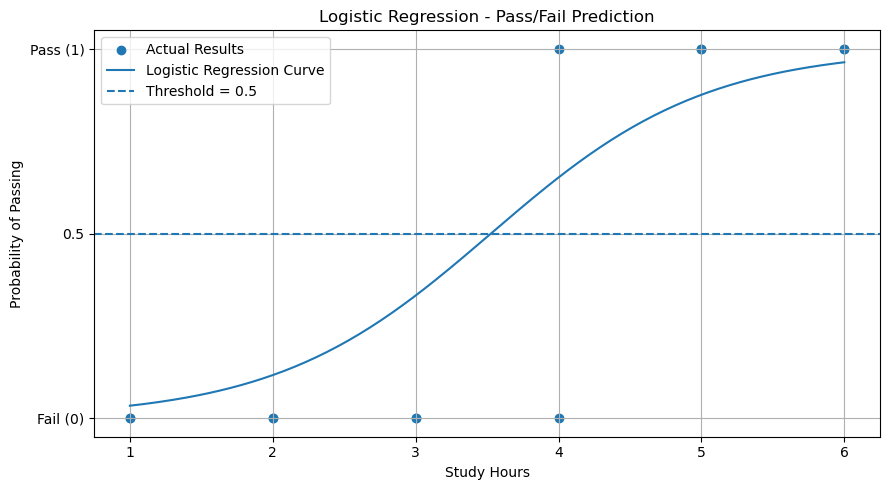

In [23]:
probabilities = model.predict_proba(study_hours)[:, pass_index]
plt.figure(figsize=(9, 5))

# Plot actual results
plt.scatter(
    df["Study_Hours"],
    df["Result"].map({"Fail": 0, "Pass": 1}),
    label="Actual Results"
)

# Plot Logistic Regression curve
plt.plot(
    study_hours,
    probabilities,
    label="Logistic Regression Curve"
)

# Display decision threshold
plt.axhline(
    y=0.5,
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression - Pass/Fail Prediction")

plt.yticks(
    [0, 0.5, 1],
    ["Fail (0)", "0.5", "Pass (1)"]
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [24]:
accuracy = accuracy_score(y_test, y_pred)

In [25]:
print("\nMODEL EVALUATION METRICS")

print("Accuracy:", accuracy * 100, "%")



MODEL EVALUATION METRICS
Accuracy: 66.66666666666666 %


In [26]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)


In [27]:
print("\nCONFUSION MATRIX")
print(cm)


CONFUSION MATRIX
[[1 1]
 [0 1]]


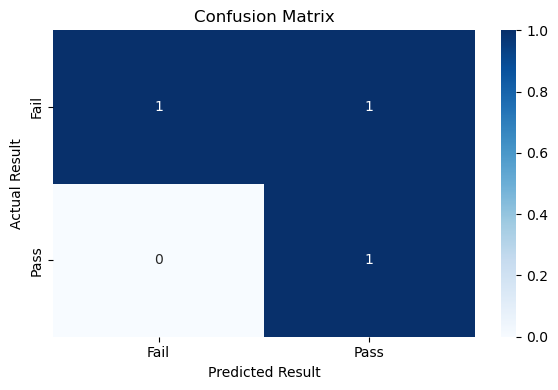

In [28]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

In [29]:
precision = precision_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)


In [30]:
print("\nPrecision:", precision)


Precision: 0.5


In [31]:
recall = recall_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)


In [32]:
print("Recall:", recall)


Recall: 1.0


In [33]:
f1 = f1_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)

In [34]:
print("F1-Score:", f1)

F1-Score: 0.6666666666666666


In [35]:
print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred,
        labels=["Fail", "Pass"],
        zero_division=0
    )
)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fail       1.00      0.50      0.67         2
        Pass       0.50      1.00      0.67         1

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3



In [36]:
new_student = pd.DataFrame({
    "Study_Hours": [5]
})

In [37]:
prediction = model.predict(new_student)

In [38]:
probability = model.predict_proba(new_student)


In [39]:
print("\nNEW STUDENT DETAILS")
print(new_student)


NEW STUDENT DETAILS
   Study_Hours
0            5


In [40]:
print("\nProbability of Fail:", probability[0][0])


Probability of Fail: 0.12442455650005035


In [41]:
print("Probability of Pass:", probability[0][1])


Probability of Pass: 0.8755754434999496


In [42]:
print("\nPREDICTED STUDENT RESULT:", prediction[0])


PREDICTED STUDENT RESULT: Pass
